# Medir qué tan bien pinta: métricas sobre la imagen real
En la clase 4 pintamos de tres formas: regla por color, K-Means y etiqueta de campo. Hoy vamos a **medir** con números.
Trabajamos siempre sobre la **imagen real** de maíz con malezas (WeedsGalore, muestra 2023-06-06, 600 × 600 píxeles). La muestra viene incluida en `assets/geospatial/weedsgalore_muestra/` (sincronizala desde GitHub; no hay que descargar nada). La [ficha de fuente](../../assets/geospatial/weedsgalore_muestra_fuente.md) describe origen y bandas.
Vamos a comparar la **regla por color** (propuesta) con la **etiqueta de campo** (referencia) y calcular **IoU, precisión, recall y F1**. Después simulamos cómo respondería **SAM** a un punto o a un recuadro.


## 1. La imagen real, la regla y la referencia
Cargamos las cinco bandas y la etiqueta (0 = fondo/suelo, 1 = maíz, 2 a 5 = malezas). La regla es ExG = 2·verde − rojo − azul con umbral en percentil 60: separa verde de no-verde, sin saber qué verde sobra.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

base = Path("../../assets/geospatial/weedsgalore_muestra")
if not base.exists():
    base = Path("assets/geospatial/weedsgalore_muestra")
nombre = "2023-06-06_0625"
bandas = {}
for banda, sufijo in [("rojo","R"),("verde","G"),("azul","B"),("borde_rojo","RE"),("nir","NIR")]:
    bandas[banda] = np.asarray(Image.open(base/"images"/f"{nombre}_{sufijo}.png"), dtype=np.float32)
etiqueta = np.asarray(Image.open(base/"semantics"/f"{nombre}.png"))
print(f"Muestra {nombre} · {etiqueta.shape[1]} × {etiqueta.shape[0]} píxeles")
print(f"Fondo/suelo: {(etiqueta==0).sum():,} · maíz: {(etiqueta==1).sum():,} · malezas: {(etiqueta>1).sum():,}")

def estirar(banda):
    baja, alta = np.percentile(banda, (2, 98))
    return np.clip((banda-baja)/(alta-baja+1e-6), 0, 1)
rgb = np.dstack((estirar(bandas["rojo"]), estirar(bandas["verde"]), estirar(bandas["azul"])))

r = bandas["rojo"].astype(float); g = bandas["verde"].astype(float); b = bandas["azul"].astype(float)
exg = 2*g - r - b
umbral = float(np.percentile(exg, 60))
regla = exg > umbral
ref_maleza = etiqueta > 1
print(f"Umbral ExG (percentil 60): {umbral:,.0f}")
print(f"Regla pinta {regla.sum():,} píxeles · maleza real: {ref_maleza.sum():,}")


Muestra 2023-06-06_0625 · 600 × 600 píxeles
Fondo/suelo: 298,883 · maíz: 24,135 · malezas: 36,982
Umbral ExG (percentil 60): 3,392
Regla pinta 143,714 píxeles · maleza real: 36,982


## 2. Comparar píxel por píxel: aciertos, sobrantes y faltantes
Cada píxel cae en una situación: **acierto** (los dos dicen maleza), **sobrante** (solo la propuesta) o **faltante** (solo la referencia). El mapa usa verde = coincidimos, rosa = pintó de más, naranja = le faltó.

Aciertos: 34,222 · Pintó de más: 109,492 · Le faltaron: 2,760
Precisión: 0.238 · Recall: 0.925 · IoU: 0.234 · F1: 0.379


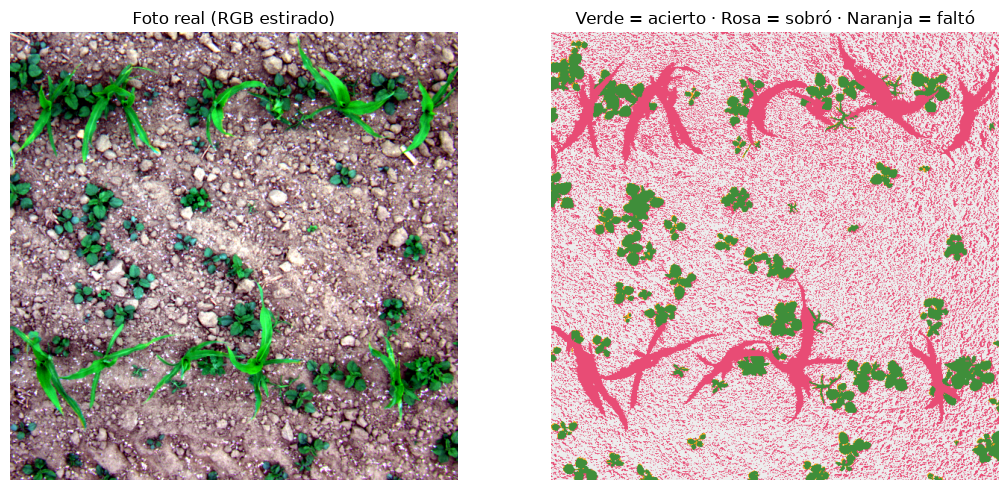

La regla encuentra casi toda la maleza (recall alto) pero marca mucho de más (precisión baja).


In [2]:
TP = int((regla & ref_maleza).sum())
FP = int((regla & ~ref_maleza).sum())
FN = int(((~regla) & ref_maleza).sum())
print(f"Aciertos: {TP:,} · Pintó de más: {FP:,} · Le faltaron: {FN:,}")
precision = TP/(TP+FP); recall = TP/(TP+FN); iou = TP/(TP+FP+FN); f1 = 2*precision*recall/(precision+recall)
print(f"Precisión: {precision:.3f} · Recall: {recall:.3f} · IoU: {iou:.3f} · F1: {f1:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(rgb); axes[0].set_title("Foto real (RGB estirado)"); axes[0].axis("off")
comparar = np.zeros(regla.shape+(3,), dtype=float); comparar[:,:] = [0.93,0.93,0.93]
comparar[(regla)&(ref_maleza)] = [0.25,0.56,0.23]
comparar[(regla)&(~ref_maleza)] = [0.91,0.30,0.46]
comparar[(~regla)&(ref_maleza)] = [1.0,0.62,0.11]
axes[1].imshow(comparar); axes[1].set_title("Verde = acierto · Rosa = sobró · Naranja = faltó"); axes[1].axis("off")
plt.tight_layout(); plt.show()
print("La regla encuentra casi toda la maleza (recall alto) pero marca mucho de más (precisión baja).")


**Ejercicio 1.** Cambiá el umbral al percentil 80 (más exigente) y volvé a correr las dos celdas. ¿Sube o baja la precisión? ¿Y el recall? Anotá qué error conviene evitar si la recorrida del lote es cara.

**Ejercicio práctico 1.** Mueve el umbral de la regla y observá cómo cambian precisión y recall.

La idea es que vean de primera mano esto: si la regla se vuelve más estricta, pinta menos, y eso tiene un efecto directo sobre la cantidad de puntos que faltan o que sobran.


In [3]:
from ipywidgets import IntSlider, Output, VBox
from IPython.display import display

# Reutilizamos los datos ya cargados en la notebook

def explorar_umbral(percentil=60):
    umbral = float(np.percentile(exg, percentil))
    propuesta = exg > umbral
    tp = int((propuesta & ref_maleza).sum())
    fp = int((propuesta & ~ref_maleza).sum())
    fn = int((~propuesta & ref_maleza).sum())
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    axes[0].imshow(rgb)
    axes[0].set_title(f"Foto real · umbral {umbral:.0f}")
    axes[0].axis("off")

    comparar = np.zeros(propuesta.shape + (3,), dtype=float)
    comparar[:] = [0.93, 0.93, 0.93]
    comparar[(propuesta) & (ref_maleza)] = [0.25, 0.56, 0.23]
    comparar[(propuesta) & (~ref_maleza)] = [0.91, 0.30, 0.46]
    comparar[(~propuesta) & (ref_maleza)] = [1.0, 0.62, 0.11]
    axes[1].imshow(comparar)
    axes[1].set_title(f"precisión={precision:.3f} · recall={recall:.3f} · IoU={iou:.3f} · F1={f1:.3f}")
    axes[1].axis("off")
    plt.tight_layout()
    display(fig)
    plt.close(fig)
    print(f"Umbral ExG: {umbral:.0f}")
    print(f"Aciertos: {tp:,} · de más: {fp:,} · faltantes: {fn:,}")
    print(f"Precisión: {precision:.3f} | Recall: {recall:.3f} | IoU: {iou:.3f} | F1: {f1:.3f}")

control_umbral = IntSlider(value=60, min=30, max=90, step=1, description="percentil")
salida_umbral = Output()

def actualizar_umbral(change=None):
    with salida_umbral:
        salida_umbral.clear_output(wait=True)
        explorar_umbral(control_umbral.value)

control_umbral.observe(actualizar_umbral, names="value")
display(VBox([control_umbral, salida_umbral]))
actualizar_umbral()


## 3. IoU, precisión, recall y F1: qué pregunta responde cada uno
**IoU** = lo común / todo lo pintado por alguien. **Precisión** = de lo pintado, cuánto era verdad (castiga pintar de más). **Recall** = de lo real, cuánto encontró (castiga que falte). **F1** combina precisión y recall en un número.

In [4]:
print(f"IoU maleza: {iou:.3f} → de todo lo pintado por alguien, coincide el {iou*100:.1f}%")
print(f"Precisión: {precision:.3f} → de lo que pintó la regla, el {precision*100:.1f}% era maleza real")
print(f"Recall: {recall:.3f} → de la maleza real, encontró el {recall*100:.1f}%")
print(f"F1: {f1:.3f} → resumen de precisión y recall")
print()
print("Lectura para el lote: recall alto + precisión baja = encontramos casi todo, pero hay que revisar mucho.")
print("Si la regla pintara menos, el recall bajaría y la precisión subiría: es un intercambio, no mejoran juntos gratis.")


IoU maleza: 0.234 → de todo lo pintado por alguien, coincide el 23.4%
Precisión: 0.238 → de lo que pintó la regla, el 23.8% era maleza real
Recall: 0.925 → de la maleza real, encontró el 92.5%
F1: 0.379 → resumen de precisión y recall

Lectura para el lote: recall alto + precisión baja = encontramos casi todo, pero hay que revisar mucho.
Si la regla pintara menos, el recall bajaría y la precisión subiría: es un intercambio, no mejoran juntos gratis.


## 4. F1 por clase: el maíz se pinta mejor que la maleza
Un solo número esconde diferencias. Calculamos F1 por separado para maíz y para malezas: la regla separa verde de suelo, así que al maíz (más verde y extenso) le va mejor que a la maleza puntual.

In [5]:
def metricas(propuesta, referencia):
    TP = int((propuesta & referencia).sum()); FP = int((propuesta & ~referencia).sum()); FN = int(((~propuesta) & referencia).sum())
    prec = TP/(TP+FP) if (TP+FP)>0 else 0.0; rec = TP/(TP+FN) if (TP+FN)>0 else 0.0
    iou = TP/(TP+FP+FN) if (TP+FP+FN)>0 else 0.0; f1 = 2*prec*rec/(prec+rec) if (prec+rec)>0 else 0.0
    return TP, FP, FN, prec, rec, iou, f1

for nombre_clase, ref in [("maíz", etiqueta==1), ("malezas", etiqueta>1), ("vegetación (maíz+maleza)", etiqueta>0)]:
    TPc, FPc, FNc, prec, rec, iouc, f1c = metricas(regla, ref)
    print(f"{nombre_clase}: IoU={iouc:.3f} · precisión={prec:.3f} · recall={rec:.3f} · F1={f1c:.3f}")
print()
print("La regla mezcla maíz y maleza en un solo grupo: por eso su F1 de vegetación supera al F1 de maleza sola.")


maíz: IoU=0.159 · precisión=0.161 · recall=0.957 · F1=0.275
malezas: IoU=0.234 · precisión=0.238 · recall=0.925 · F1=0.379
vegetación (maíz+maleza): IoU=0.388 · precisión=0.399 · recall=0.938 · F1=0.560

La regla mezcla maíz y maleza en un solo grupo: por eso su F1 de vegetación supera al F1 de maleza sola.


**Ejercicio 2.** Mirá los tres F1: ¿para qué clase sirve la regla y para cuál no? Escribí en una frase por qué un F1 alto en vegetación no prueba que identifique malezas.

## 5. SAM: un punto o un recuadro proponen la forma (simulación)
SAM no decide qué es maleza: recibe una **indicación** y devuelve la forma. Lo simulamos con la referencia como si fuera un SAM ideal: el punto devuelve la planta conectada que lo contiene; el recuadro devuelve lo que hay adentro. En la práctica real, SAM propondría el contorno y una persona le pondría el nombre comparando con el campo.

Plantas de maleza conectadas en la referencia: 81
Punto en (300,300) → planta 43 con 1,267 píxeles


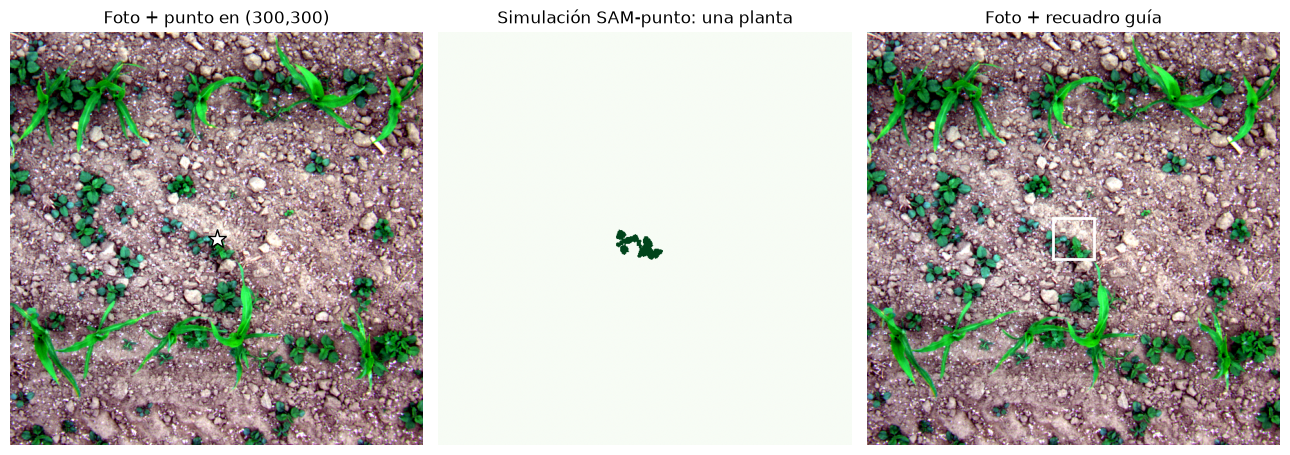

La forma sale bien, pero el nombre 'maleza' lo pusimos nosotros al comparar con la referencia.


In [6]:
from scipy import ndimage
instancias, n_plantas = ndimage.label(etiqueta > 1)
print(f"Plantas de maleza conectadas en la referencia: {n_plantas}")

# Punto indicado por el usuario (dentro de una maleza real)
py, px = 300, 300
# buscar un punto con maleza cercana si cae en suelo
if not (etiqueta[py, px] > 1):
    ys, xs = np.where(etiqueta > 1)
    d2 = (ys-py)**2 + (xs-px)**2
    py, px = int(ys[d2.argmin()]), int(xs[d2.argmin()])
id_planta = int(instancias[py, px])
propuesta_punto = instancias == id_planta
print(f"Punto en ({py},{px}) → planta {id_planta} con {propuesta_punto.sum():,} píxeles")

# Recuadro indicado por el usuario (60 × 60 alrededor del punto)
ry0, ry1, rx0, rx1 = max(0,py-30), py+30, max(0,px-30), px+30
propuesta_caja = np.zeros_like(etiqueta, dtype=bool)
propuesta_caja[ry0:ry1, rx0:rx1] = (etiqueta[ry0:ry1, rx0:rx1] > 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
axes[0].imshow(rgb); axes[0].plot(px, py, marker="*", color="white", markersize=14, markeredgecolor="black")
axes[0].set_title(f"Foto + punto en ({py},{px})"); axes[0].axis("off")
axes[1].imshow(propuesta_punto, cmap="Greens"); axes[1].set_title("Simulación SAM-punto: una planta"); axes[1].axis("off")
axes[2].imshow(rgb); axes[2].add_patch(plt.Rectangle((rx0,ry0),rx1-rx0,ry1-ry0, fill=False, edgecolor="white", lw=2))
axes[2].set_title("Foto + recuadro guía"); axes[2].axis("off")
plt.tight_layout(); plt.show()
print("La forma sale bien, pero el nombre 'maleza' lo pusimos nosotros al comparar con la referencia.")


In [7]:
from ipywidgets import IntSlider, Output, VBox
from IPython.display import display

def explorar_prompt(px=300, py=300, ancho=60):
    # Si cae en suelo, se mueve al píxel de maleza más cercano
    if not (etiqueta[py, px] > 1):
        ys, xs = np.where(etiqueta > 1)
        d2 = (ys - py) ** 2 + (xs - px) ** 2
        py, px = int(ys[d2.argmin()]), int(xs[d2.argmin()])

    id_planta = int(instancias[py, px])
    propuesta_punto = instancias == id_planta
    ry0, ry1 = max(0, py - ancho // 2), min(etiqueta.shape[0], py + ancho // 2)
    rx0, rx1 = max(0, px - ancho // 2), min(etiqueta.shape[1], px + ancho // 2)
    propuesta_caja = np.zeros_like(etiqueta, dtype=bool)
    propuesta_caja[ry0:ry1, rx0:rx1] = (etiqueta[ry0:ry1, rx0:rx1] > 1)

    fig, axes = plt.subplots(1, 3, figsize=(13, 5))
    axes[0].imshow(rgb)
    axes[0].plot(px, py, marker="*", color="white", markersize=14, markeredgecolor="black")
    axes[0].set_title(f"Punto elegido: ({py}, {px})")
    axes[0].axis("off")

    axes[1].imshow(propuesta_punto, cmap="Greens")
    axes[1].set_title(f"Planta seleccionada: {propuesta_punto.sum():,} px")
    axes[1].axis("off")

    axes[2].imshow(rgb)
    axes[2].add_patch(plt.Rectangle((rx0, ry0), rx1 - rx0, ry1 - ry0, fill=False, edgecolor="white", lw=2))
    axes[2].set_title(f"Recuadro guía ({ancho} px)")
    axes[2].axis("off")
    plt.tight_layout()
    display(fig)
    plt.close(fig)

    print(f"Punto en ({py},{px}) → planta {id_planta} · {propuesta_punto.sum():,} píxeles")
    print(f"Dentro del recuadro: {propuesta_caja.sum():,} píxeles de maleza")
    print("¿Qué cambia si elegís otro punto? El contorno cambia, y con él cambia la interpretación del prompt.")

control_px = IntSlider(value=300, min=10, max=590, step=10, description="px")
control_py = IntSlider(value=300, min=10, max=590, step=10, description="py")
control_ancho = IntSlider(value=60, min=20, max=120, step=10, description="ancho")
salida_prompt = Output()

def actualizar_prompt(change=None):
    with salida_prompt:
        salida_prompt.clear_output(wait=True)
        explorar_prompt(control_px.value, control_py.value, control_ancho.value)

for control in (control_px, control_py, control_ancho):
    control.observe(actualizar_prompt, names="value")
display(VBox([control_px, control_py, control_ancho, salida_prompt]))
actualizar_prompt()


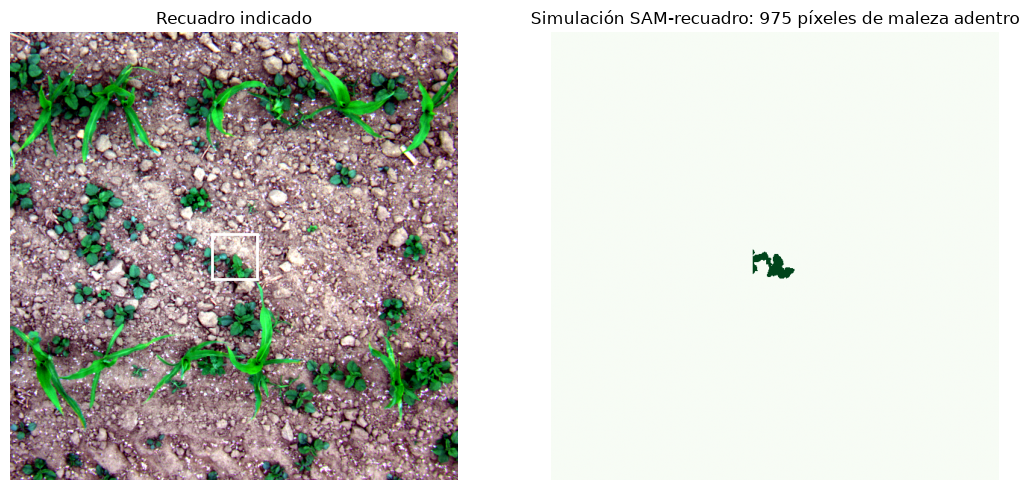

Todo lo propuesto cae en maleza real: 975 píxeles. Sin la referencia, SAM no sabría si es maíz o maleza.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(rgb)
axes[0].add_patch(plt.Rectangle((rx0,ry0),rx1-rx0,ry1-ry0, fill=False, edgecolor="white", lw=2))
axes[0].set_title("Recuadro indicado"); axes[0].axis("off")
axes[1].imshow(propuesta_caja, cmap="Greens")
axes[1].set_title(f"Simulación SAM-recuadro: {propuesta_caja.sum():,} píxeles de maleza adentro"); axes[1].axis("off")
plt.tight_layout(); plt.show()
TPs = int((propuesta_caja & (etiqueta>1)).sum())
print(f"Todo lo propuesto cae en maleza real: {TPs:,} píxeles. Sin la referencia, SAM no sabría si es maíz o maleza.")


**Ejercicio 3.** Mové el punto a una zona de maíz (por ejemplo, buscá un píxel con etiqueta 1) y repetí la celda. ¿Qué devuelve la simulación? ¿Quién decide si eso sobra o sirve en ese lote?

## 6. Cierre: medir no reemplaza ir al campo
La regla tiene IoU bajo en maleza porque mezcla maíz y maleza: encuentra vegetación, no identifica. SAM recorta bien con una indicación, pero tampoco nombra. El número (IoU, F1) mide el contorno; la etiqueta 'maleza' se valida con alguien que sepa qué se sembró. Y un buen número en esta imagen no garantiza lo mismo en otro lote, otro día u otra resolución: hay que repetir la medición allá.